# Gaussian processes for fast multifidelity analysis of Airfoils 

This experiment explores methods for combining multifidelity data to reconstruct a response surface. A surrogate aerodynamic model is used for its fast availability and meaningful outputs. 

In [9]:
%pip install numpy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [ ]:
## load important modules 

import aerosandbox as asb 
import numpy as np 
from matplotlib import pyplot as plt 

H


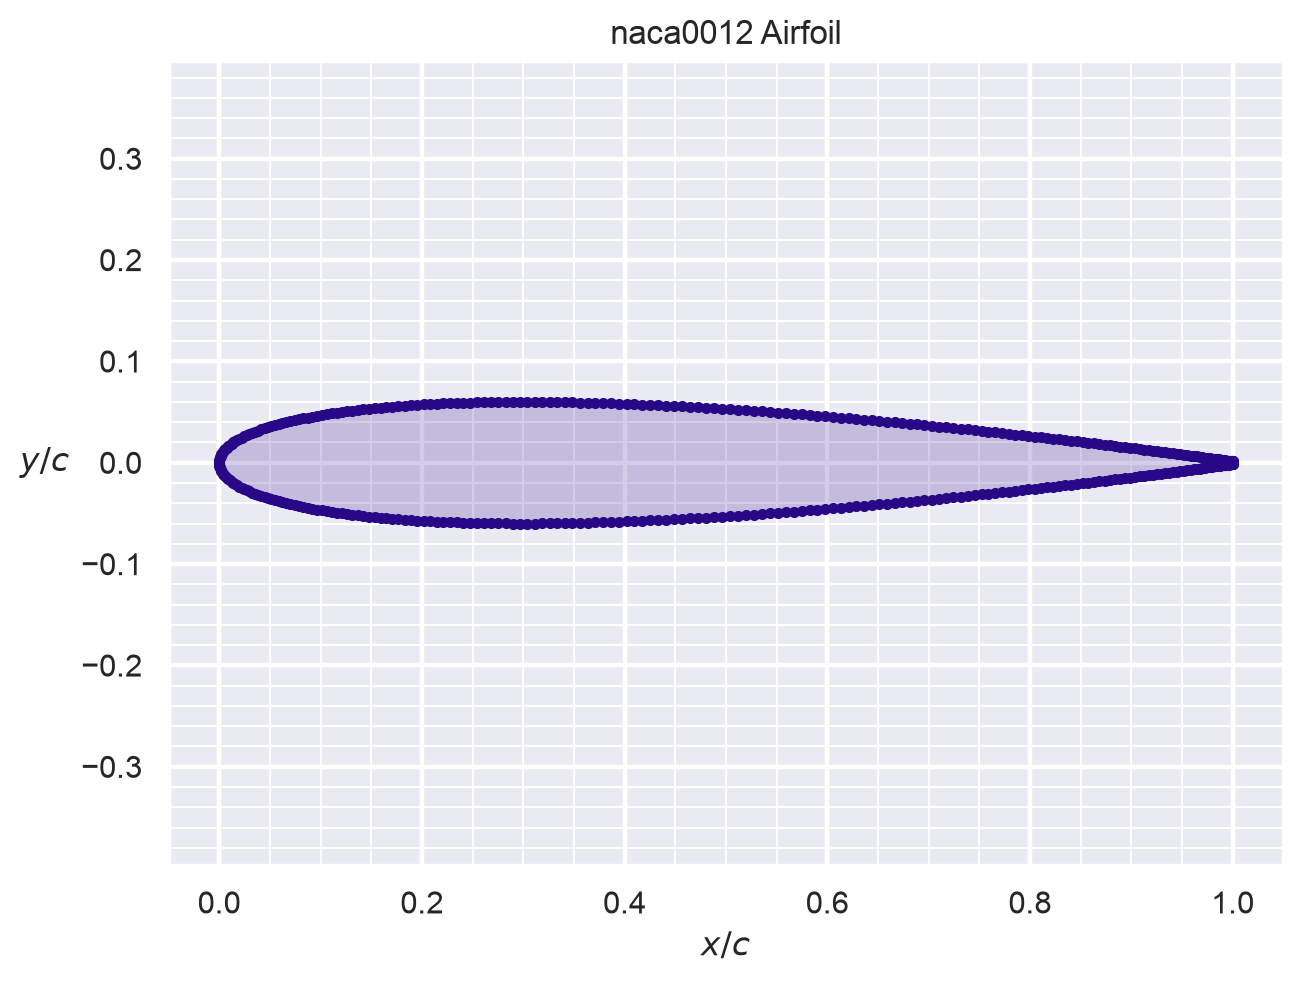

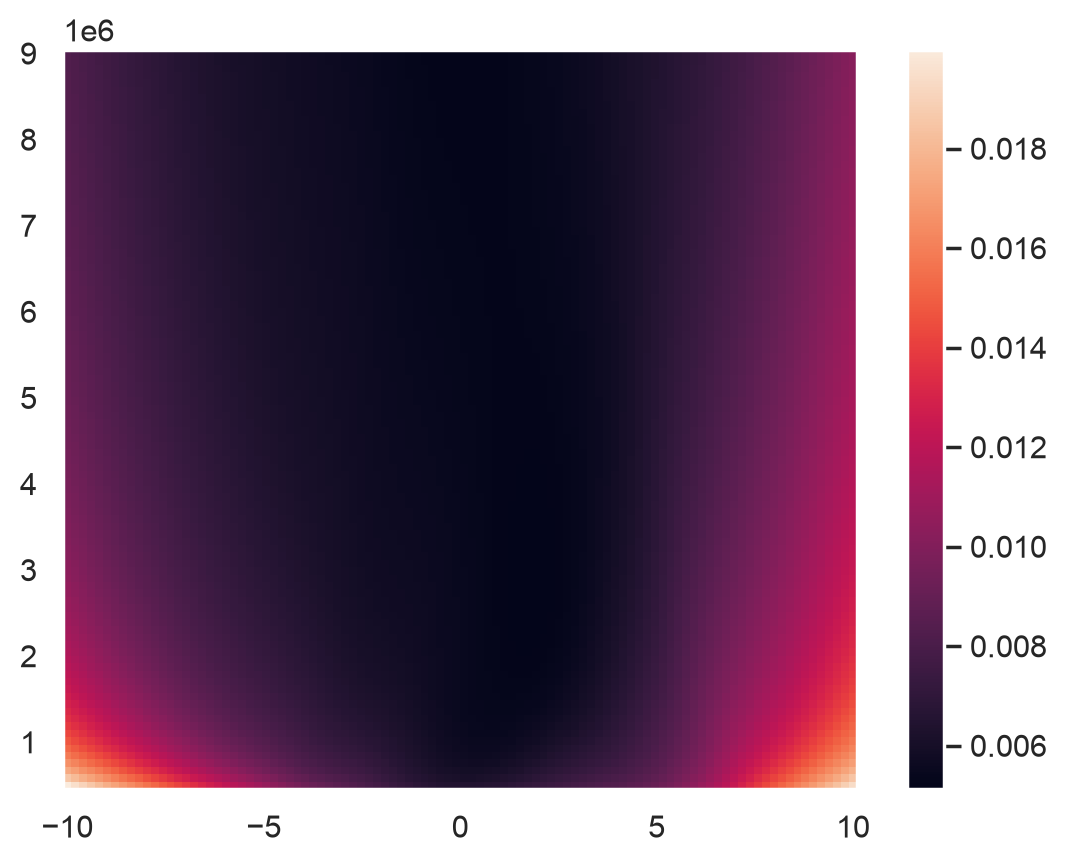

In [ ]:
## Define initial airfoil and operating points 

airfoil = asb.Airfoil('naca2412')
# airfoil.draw(backend="matplotlib")

## operating points 

alpha_min, alpha_max = -10, 10
re_min, re_max = 5e5, 9e6

N_alpha, N_re = 100, 100 

alpha = np.linspace(alpha_min, alpha_max, N_alpha)
re = np.linspace(re_min, re_max, N_re)

a, r = np.meshgrid(alpha, re, indexing="ij")

aero = airfoil.get_aero_from_neuralfoil(alpha=a.flatten(), Re=r.flatten())

# plot the figure 
plt.figure()
pmesh = plt.pcolormesh(a, r, aero['CD'].reshape(N_alpha, N_re))
plt.colorbar(pmesh)

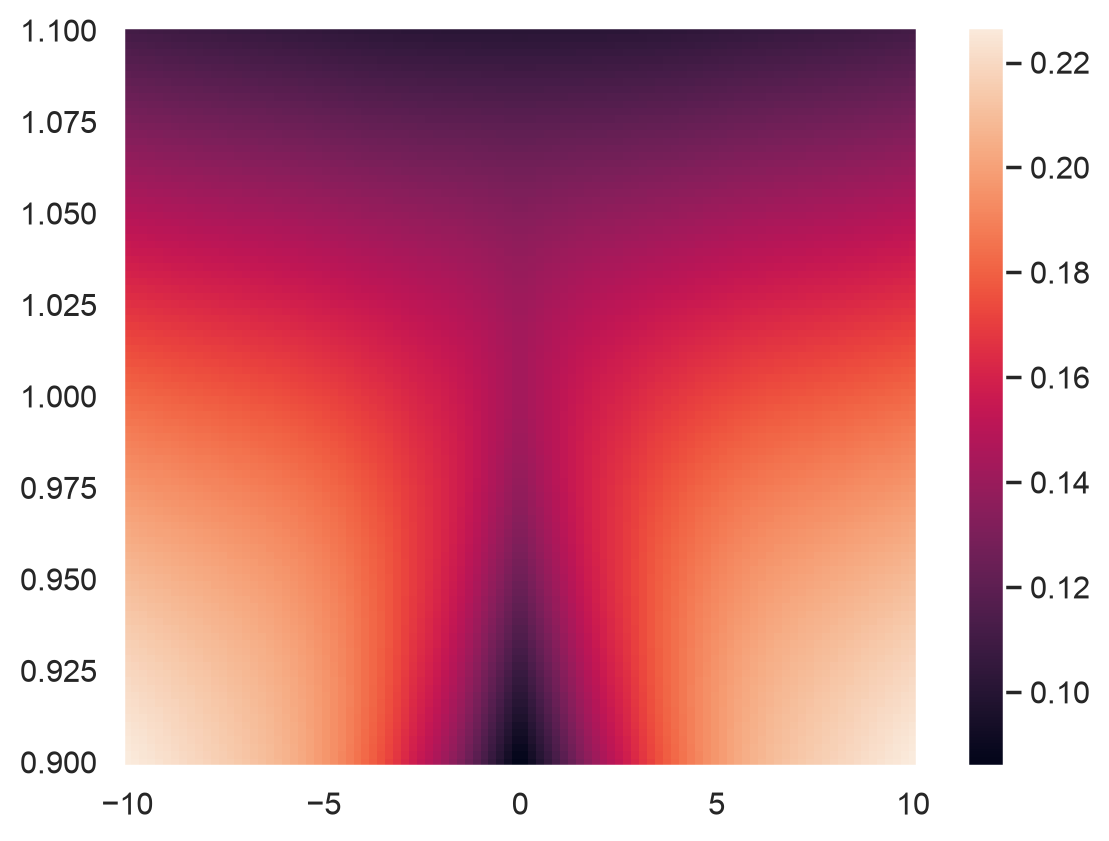

In [ ]:
# similar experiments varying this time the mach number 

airfoil = asb.Airfoil('naca0012')

## operating points 

alpha_min, alpha_max = -10, 10
mach_min, mach_max = 0.9, 1.1

N_alpha, N_mach = 100, 100

alpha = np.linspace(alpha_min, alpha_max, N_alpha)
mach = np.linspace(mach_min, mach_max, N_mach)

a, m = np.meshgrid(alpha, mach, indexing="ij")

aero = airfoil.get_aero_from_neuralfoil(alpha=a.flatten(), Re=1e6, mach=m.flatten(), model_size="xxxlarge")

aero_levels = [
    airfoil.get_aero_from_neuralfoil(alpha=a.flatten(), Re=1e6, mach=m.flatten(), model_size=model_size)
    for model_size in ["xxxlarge", "xxlarge", "xlarge", "large", "small", "xsmall", "xxsmall"]
]


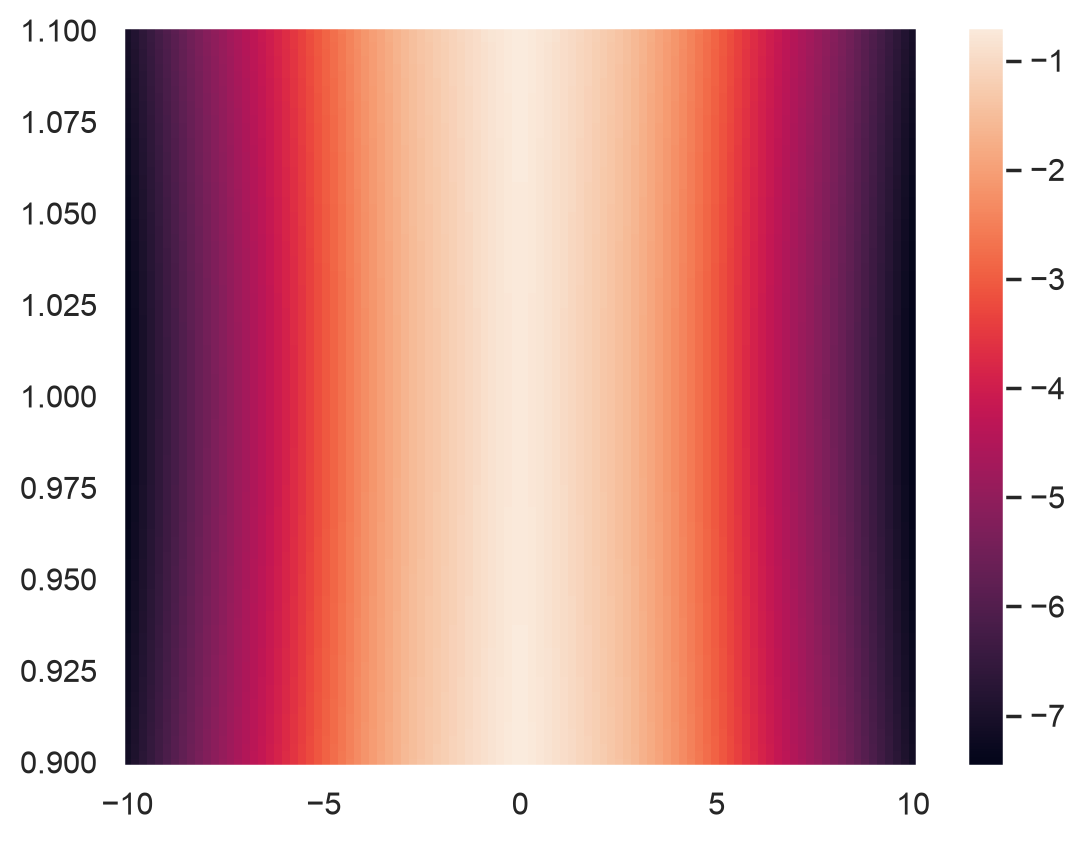

In [55]:
plt.figure() 
pmesh = plt.pcolormesh(a, m, aero['Cpmin'].reshape(N_alpha, N_mach))
plt.colorbar(pmesh)

In [70]:
airfoil = asb.Airfoil("naca2412")

xtr_uppers = np.linspace(0, 1, 100)
alpha = np.linspace(-10, 10, 100)

a, x = np.meshgrid(alpha, xtr_uppers, indexing="ij")

aero = airfoil.get_aero_from_neuralfoil(alpha=a.flatten(), Re=1e6, xtr_upper=x.flatten(), model_size="xxxlarge")

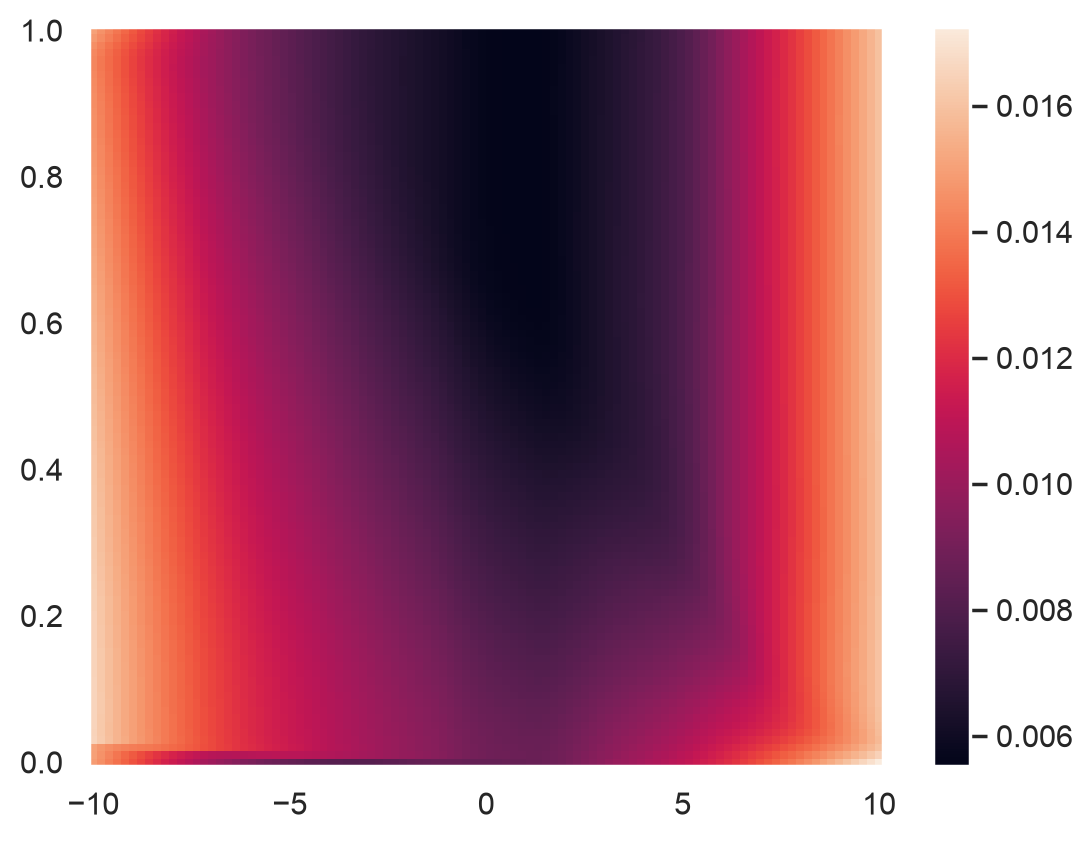

In [71]:
plt.figure()
pmesh = plt.pcolormesh(a, x, aero['CD'].reshape(100, 100))
plt.colorbar(pmesh)